# 02 — Non-Gaussian potential $\Phi^{\rm NG}$ (local), Schwinger core

Phase 2: the heart of GENGARS. We generate $\Phi^{\rm NG}$ with the Schwinger-parameterized kernel (`jaxpng.phing.phiNG`) for the **local** template and validate it:
1. **Anchor** — for local $W=1$, so $\Phi^{\rm NG}(x)=\Phi^{\rm G}(x)^2-\langle\Phi^{\rm G2}\rangle$ (exact).
2. **Convergence** — the t-integral error $\to 0$ (2nd order) as the grid refines.
3. **Bispectrum** — $\Phi=\Phi^{\rm G}+f_{\rm NL}\Phi^{\rm NG}$ has $B_\Phi=2f_{\rm NL}[P_\Phi P_\Phi+\text{2 perm}]$.

Kernel **Python (jaxpng)**.

In [1]:
import numpy as np
import jax, jax.numpy as jnp
import matplotlib.pyplot as plt
import jaxpng
from jaxpng import cosmology as C, gaussian, bispectra, phing, measure
from jaxpng.config import Box
TK='../../gengars/inputs/planck18_transfer.dat'
cosmo=C.make_cosmo(TK, omega_m=0.3175, omega_l=0.6825, omega_b=0.049,
                   hubble=0.6711, n_s=0.9624, sigma8=0.834, sigma8_norm=True)
n_s=cosmo.n_s; box=Box(N=64, L=1000.0)
print('jax', jax.__version__, jax.devices())

jax 0.10.1 [CpuDevice(id=0)]


## Generate $\Phi^{\rm G}$, then $\Phi^{\rm NG}$ (local), and the exact target

In [2]:
w=jax.random.normal(jax.random.PRNGKey(0), box.rshape)
phiG_k=gaussian.phiG_from_white_noise(w, cosmo, box)
phiG_x=jnp.fft.irfftn(phiG_k, s=box.rshape)
tmpl=bispectra.local(n_s)
phiNG_k=phing.phiNG(phiG_k, tmpl, box, n_s, per_efold=20.0)
phiNG_x=jnp.fft.irfftn(phiNG_k, s=box.rshape)
target=phiG_x**2 - jnp.mean(phiG_x**2)         # local anchor
relerr=float(jnp.linalg.norm(phiNG_x-target)/jnp.linalg.norm(target))
print('relative L2 error  Phi^NG vs (Phi^G^2 - mean) =', relerr)

relative L2 error  Phi^NG vs (Phi^G^2 - mean) = 0.0004166181613904953


### Visual anchor: $\Phi^{\rm NG}$ vs $\Phi^{\rm G2}-\langle\cdot\rangle$ (mid-plane slice)

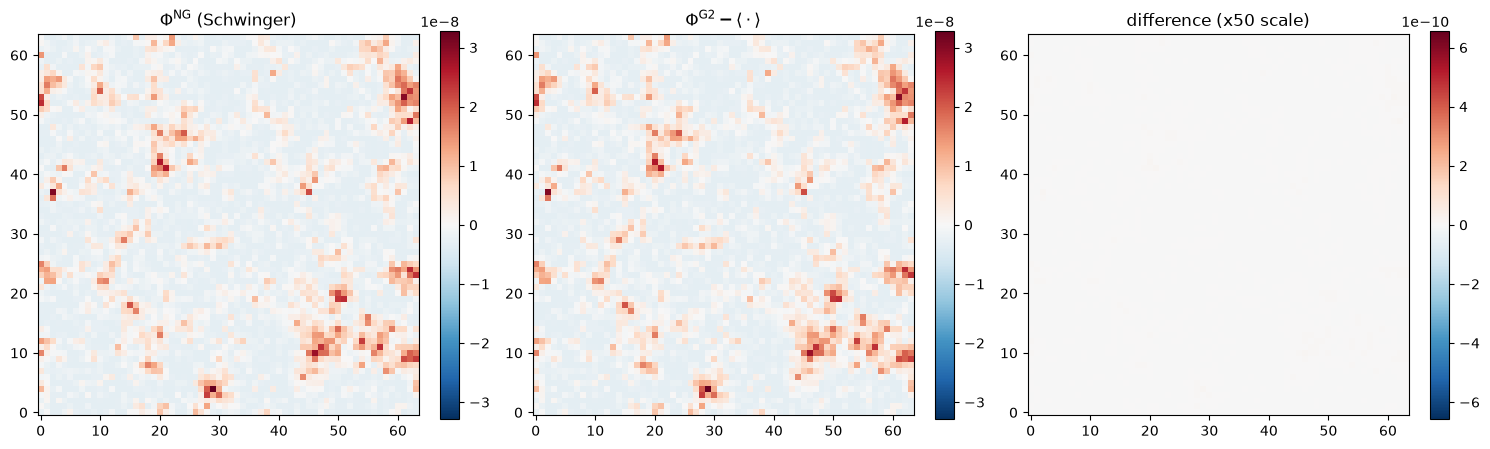

In [3]:
sl=lambda f: np.asarray(f[box.N//2])
A,Bt=sl(phiNG_x), sl(target); D=A-Bt
v=np.max(np.abs(Bt))
fig,ax=plt.subplots(1,3,figsize=(15,4.6))
for a,dat,ti,vv in [(ax[0],A,'$\\Phi^{\\rm NG}$ (Schwinger)',v),(ax[1],Bt,'$\\Phi^{\\rm G2}-\\langle\\cdot\\rangle$',v),(ax[2],D,'difference (x50 scale)',v*0.02)]:
    im=a.imshow(dat,origin='lower',cmap='RdBu_r',vmin=-vv,vmax=vv); a.set_title(ti)
    plt.colorbar(im,ax=a,fraction=0.046)
plt.tight_layout(); plt.show()

## t-integral convergence (anchor error vs number of Schwinger steps)

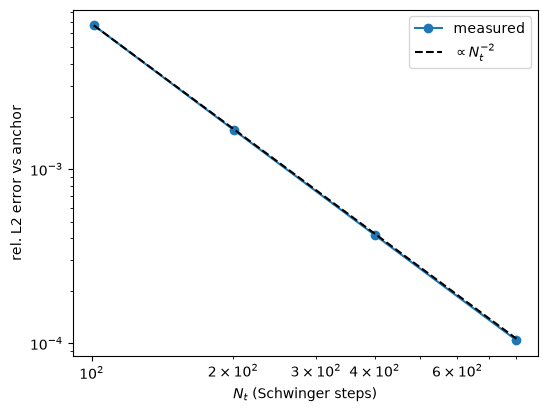

errors: {101: '6.68e-03', 201: '1.67e-03', 401: '4.17e-04', 801: '1.04e-04'}


In [4]:
pes=[5,10,20,40]; errs=[]; Nts=[]
for pe in pes:
    ng=jnp.fft.irfftn(phing.phiNG(phiG_k,tmpl,box,n_s,per_efold=pe),s=box.rshape)
    t,_=phing.schwinger_t_grid(box,per_efold=pe)
    Nts.append(len(t)); errs.append(float(jnp.linalg.norm(ng-target)/jnp.linalg.norm(target)))
Nts=np.array(Nts); errs=np.array(errs)
plt.figure(figsize=(6,4.5))
plt.loglog(Nts,errs,'o-',label='measured')
plt.loglog(Nts, errs[0]*(Nts[0]/Nts)**2,'k--',label='$\\propto N_t^{-2}$')
plt.xlabel('$N_t$ (Schwinger steps)'); plt.ylabel('rel. L2 error vs anchor'); plt.legend(); plt.show()
print('errors:', dict(zip(Nts.tolist(), [f'{e:.2e}' for e in errs])))

## Bispectrum of $\Phi=\Phi^{\rm G}+f_{\rm NL}\Phi^{\rm NG}$ vs target $6 f_{\rm NL}P_\Phi^2$

The physical potential is tiny ($\sigma_\Phi\sim5\times10^{-5}$), so the PNG bispectrum sits far below the Gaussian cosmic variance. We use **paired realizations**: for each white-noise seed, measure $B$ of the PNG field $\Phi$ and of its **Gaussian counterpart** $\Phi^{\rm G}$ (same seed), and take $\Delta B = B[\Phi]-B[\Phi^{\rm G}]$. The Gaussian piece (the dominant noise) is common to both and cancels, isolating the signal even at $f_{\rm NL}=100$. Uses the real Schwinger $\Phi^{\rm NG}$.

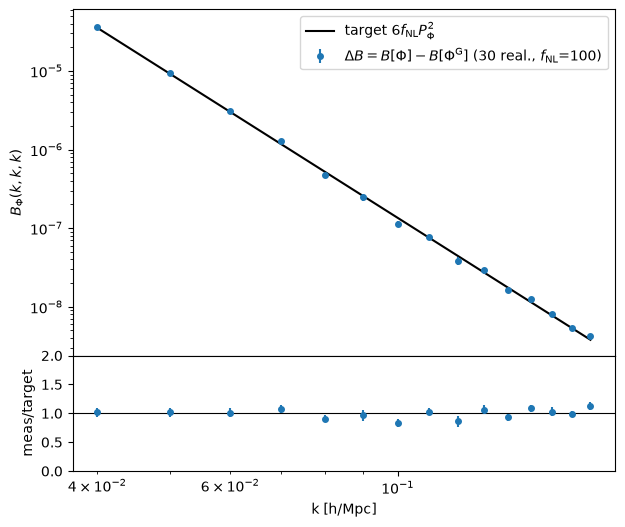

mean ratio = 0.996 +/- 0.081  over 15 k-bins


In [5]:
fNL=100.0; nreal=30; ks=np.linspace(0.04, 0.18, 15); theta=measure.EQUILATERAL_THETA
keys=jax.random.split(jax.random.PRNGKey(7), nreal)
dB=np.zeros((nreal,len(ks)))
for r,key in enumerate(keys):
    ww=jax.random.normal(key, box.rshape)
    pg=gaussian.phiG_from_white_noise(ww, cosmo, box)
    phi=pg + fNL*phing.phiNG(pg, tmpl, box, n_s, per_efold=20.0)
    for j,k in enumerate(ks):
        BNG=float(measure.bispectrum(phi, box.L, float(k), float(k), theta)['B'][0])
        BG =float(measure.bispectrum(pg,  box.L, float(k), float(k), theta)['B'][0])
        dB[r,j]=BNG-BG
dBm=dB.mean(0); dBe=dB.std(0)/np.sqrt(nreal)
Ptar=np.asarray(C.power_phi(cosmo, jnp.asarray(ks))); Btar=6.0*fNL*Ptar**2
fig,(a0,a1)=plt.subplots(2,1,figsize=(7,6),sharex=True,gridspec_kw=dict(height_ratios=[3,1],hspace=0))
a0.loglog(ks,Btar,'k-',label='target $6f_{\\rm NL}P_\\Phi^2$')
a0.errorbar(ks,dBm,yerr=dBe,fmt='C0o',ms=4,label='$\\Delta B=B[\\Phi]-B[\\Phi^{\\rm G}]$ (%d real., $f_{\\rm NL}$=%d)'%(nreal,int(fNL)))
a0.set_ylabel('$B_\\Phi(k,k,k)$'); a0.legend()
a1.errorbar(ks,dBm/Btar,yerr=dBe/Btar,fmt='C0o',ms=4); a1.axhline(1,color='k',lw=.8); a1.set_ylim(0,2)
a1.set_ylabel('meas/target'); a1.set_xlabel('k [h/Mpc]'); plt.show()
print('mean ratio = %.3f +/- %.3f  over %d k-bins'%(np.mean(dBm/Btar), np.std(dBm/Btar), len(ks)))

**Phase 2 OK**: the Schwinger $\Phi^{\rm NG}$ matches the local anchor to $\sim10^{-4}$, and with paired-Gaussian subtraction the recovered bispectrum matches $2f_{\rm NL}[P_\Phi P_\Phi+\text{perm}]$ at $f_{\rm NL}=100$. Next: Phase 3 — equilateral & orthogonal.